# 02 — MVTec: HPO log preprocessing

Loads the raw Optuna SQLite log from notebook 01, filters to the 9,976 COMPLETE trials,
selects and types the 13 hard/soft configuration columns plus the validation-F1 target, and
writes the surrogate-ready table (`surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv`)
consumed by every downstream MVTec notebook. Implements Section 3.3 of the paper.

Also produces the preprocessing diagnostics (F1 distribution, best-so-far curve,
F1-by-hyperparameter boxplots) under `figures_preprocessing/` and `tables_preprocessing/`.


In [1]:
from pathlib import Path
import json
import sqlite3

import optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 180)

# ------------------------------------------------------------
# Robust project/root detection
# ------------------------------------------------------------

CWD = Path.cwd()
print("Current working directory:")
print(CWD)

DB_FILENAME = "mvtec_4class_patchcore_hpo_logs.db"

candidate_paths = []

# Common locations depending on where the notebook is opened from
candidate_paths.extend([
    CWD / DB_FILENAME,
    CWD / "outputs_patchcore" / DB_FILENAME,
    CWD / "hpo_mvtec_4class" / "outputs_patchcore" / DB_FILENAME,
    CWD.parent / "outputs_patchcore" / DB_FILENAME,
    CWD.parent / "hpo_mvtec_4class" / "outputs_patchcore" / DB_FILENAME,
])

# Recursive search from current directory and parent, limited to this filename
for base in [CWD, CWD.parent]:
    try:
        candidate_paths.extend(base.rglob(DB_FILENAME))
    except Exception:
        pass

# Remove duplicates while preserving order
seen = set()
candidate_paths_unique = []
for p in candidate_paths:
    p = p.resolve()
    if p not in seen:
        seen.add(p)
        candidate_paths_unique.append(p)

print("\nCandidate DB paths:")
db_candidates_existing = []

for p in candidate_paths_unique:
    exists = p.exists()
    size_mb = p.stat().st_size / (1024 * 1024) if exists else 0
    print(f"- exists={exists:<5} size={size_mb:8.3f} MB | {p}")
    if exists:
        db_candidates_existing.append(p)

if not db_candidates_existing:
    raise FileNotFoundError(
        "Could not find mvtec_4class_patchcore_hpo_logs.db. "
        "Check where the notebook is running from using Path.cwd()."
    )

# Pick the largest existing DB by default.
# This avoids accidentally using an empty DB created by a wrong path.
DB_PATH = max(db_candidates_existing, key=lambda p: p.stat().st_size)

print("\nSelected DB:")
print(DB_PATH)
print("Size MB:", DB_PATH.stat().st_size / (1024 * 1024))

# Define project root from the selected DB location
OUTPUTS_DIR = DB_PATH.parent
ROOT = OUTPUTS_DIR.parent

SURROGATE_DIR = ROOT / "surrogate_ready_dataset"
FIG_DIR = ROOT / "figures_preprocessing"
TABLE_DIR = ROOT / "tables_preprocessing"

SURROGATE_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

BEST_PARAMS_PATH = OUTPUTS_DIR / "best_params.json"
BEST_RESULTS_PATH = OUTPUTS_DIR / "best_params_final_results.csv"

print("\nResolved paths:")
print("ROOT:", ROOT)
print("OUTPUTS_DIR:", OUTPUTS_DIR)
print("SURROGATE_DIR:", SURROGATE_DIR)
print("FIG_DIR:", FIG_DIR)
print("TABLE_DIR:", TABLE_DIR)

print("\nFile checks:")
print("DB exists:", DB_PATH.exists(), DB_PATH)
print("Best params JSON exists:", BEST_PARAMS_PATH.exists(), BEST_PARAMS_PATH)
print("Best final results CSV exists:", BEST_RESULTS_PATH.exists(), BEST_RESULTS_PATH)

Current working directory:
/home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec

Candidate DB paths:
- exists=0     size=   0.000 MB | /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/mvtec_4class_patchcore_hpo_logs.db
- exists=1     size=  41.445 MB | /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/outputs_patchcore/mvtec_4class_patchcore_hpo_logs.db
- exists=0     size=   0.000 MB | /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/hpo_mvtec_4class/outputs_patchcore/mvtec_4class_patchcore_hpo_logs.db
- exists=0     size=   0.000 MB | /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/outputs_patchcore/mvtec_4class_patchcore_hpo_logs.db
- exists=0     size=   0.000 MB | /home/jovyan/fast

In [2]:
# ------------------------------------------------------------
# Inspect SQLite content before loading with Optuna
# ------------------------------------------------------------

def inspect_sqlite_db(db_path):
    with sqlite3.connect(db_path) as conn:
        tables = pd.read_sql_query(
            "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;",
            conn
        )

        print("SQLite tables:")
        display(tables)

        if "studies" in tables["name"].tolist():
            studies_sql = pd.read_sql_query("SELECT * FROM studies;", conn)
            print("\nStudies table:")
            display(studies_sql)
        else:
            print("\nWARNING: No 'studies' table found. This may not be an Optuna RDB database.")

inspect_sqlite_db(DB_PATH)

# Use absolute path for Optuna storage
STORAGE = f"sqlite:///{DB_PATH.resolve().as_posix()}"

summaries = optuna.get_all_study_summaries(storage=STORAGE)

print("\nOptuna studies found:", len(summaries))

for i, s in enumerate(summaries):
    best_value = s.best_trial.value if s.best_trial is not None else None
    print(
        f"{i}: name={s.study_name} | trials={s.n_trials} | "
        f"direction={s.direction} | best={best_value}"
    )

if len(summaries) == 0:
    raise ValueError(
        "Optuna found 0 studies in the selected database. "
        "Check the SQLite tables printed above. If the selected DB is very small, "
        "you may have accidentally created an empty DB from the earlier wrong path."
    )

SQLite tables:


,name
0,alembic_version
1,studies
2,study_directions
3,study_system_attributes
4,study_user_attributes
5,trial_heartbeats
6,trial_intermediate_values
7,trial_params
8,trial_system_attributes
9,trial_user_attributes



Studies table:


,study_id,study_name
0,1,mvtec_4class_patchcore_bottle_cable_capsule_hazelnut_v1.0.0



Optuna studies found: 1
0: name=mvtec_4class_patchcore_bottle_cable_capsule_hazelnut_v1.0.0 | trials=10000 | direction=2 | best=0.8202491952491952


In [3]:
STUDY_NAME = summaries[0].study_name

study = optuna.load_study(
    study_name=STUDY_NAME,
    storage=STORAGE
)

print("Loaded study:", study.study_name)
print("Number of trials:", len(study.trials))
print("Best value:", study.best_value)
print("Best trial:", study.best_trial.number)

Loaded study: mvtec_4class_patchcore_bottle_cable_capsule_hazelnut_v1.0.0
Number of trials: 10000
Best value: 0.8202491952491952
Best trial: 4545


In [4]:
df_raw = study.trials_dataframe(
    attrs=("number", "value", "state", "params", "user_attrs")
)

print("Raw trials dataframe:", df_raw.shape)
display(df_raw.head())
display(df_raw.head().T)

Raw trials dataframe: (10000, 22)


,number,value,state,params_backbone,params_batch_size,params_center_crop_key,params_coreset_sampling_ratio,params_image_size_key,params_layers_key,params_max_patches_per_image,params_num_neighbors,params_pre_trained,params_reduction,params_soft_corruption_level,params_soft_review_budget,params_soft_train_fraction,user_attrs_mean_auroc_val,user_attrs_mean_f1_val_at_budget,user_attrs_oom,user_attrs_per_class_metrics,user_attrs_runtime_sec,user_attrs_selected_classes
0,0,0.569961,COMPLETE,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50,0.678196,0.569961,False,"{'bottle': {'threshold_val_budget': 38.598319342136385, 'precision_val_at_budget': 0.7857142857142857, 'recall_val_at_budget': 0.3548387096774194, 'f1_val_at_budget': 0.4888888...",20.316875,"[bottle, cable, capsule, hazelnut]"
1,1,NaN,FAIL,resnet34,8,0.875,0.099,320,l2,128,26,True,mean,none,0.11,0.61,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0.564978,COMPLETE,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50,0.652818,0.564978,False,"{'bottle': {'threshold_val_budget': 38.806255140304565, 'precision_val_at_budget': 0.7857142857142857, 'recall_val_at_budget': 0.3548387096774194, 'f1_val_at_budget': 0.4888888...",18.072773,"[bottle, cable, capsule, hazelnut]"
3,3,0.288997,COMPLETE,resnet34,8,0.875,0.099,320,l2,128,26,True,mean,none,0.11,0.61,0.803638,0.288997,False,"{'bottle': {'threshold_val_budget': 2.3016514110193107, 'precision_val_at_budget': 1.0, 'recall_val_at_budget': 0.16129032258064516, 'f1_val_at_budget': 0.2777777777777778, 'au...",16.241471,"[bottle, cable, capsule, hazelnut]"
4,4,0.332794,COMPLETE,resnet34,8,0.875,0.003,256,l2_l3,512,25,True,max,strong,0.22,0.66,0.477085,0.332794,False,"{'bottle': {'threshold_val_budget': 16.043874111175537, 'precision_val_at_budget': 0.6, 'recall_val_at_budget': 0.1935483870967742, 'f1_val_at_budget': 0.2926829268292683, 'aur...",38.320007,"[bottle, cable, capsule, hazelnut]"


,0,1,2,3,4
number,0,1,2,3,4
value,0.569961,NaN,0.564978,0.288997,0.332794
state,COMPLETE,FAIL,COMPLETE,COMPLETE,COMPLETE
params_backbone,wide_resnet50_2,resnet34,wide_resnet50_2,resnet34,resnet34
params_batch_size,8,8,8,8,8
params_center_crop_key,0.875,0.875,0.875,0.875,0.875
params_coreset_sampling_ratio,0.055,0.099,0.055,0.099,0.003
params_image_size_key,256,320,256,320,256
params_layers_key,l3,l2,l3,l2,l2_l3
params_max_patches_per_image,1024,128,1024,128,512


In [5]:
df = df_raw[df_raw["state"] == "COMPLETE"].copy()

df["value"] = pd.to_numeric(df["value"], errors="coerce")
df = df.dropna(subset=["value"]).reset_index(drop=True)

print("Complete trials with valid value:", df.shape)
print("Best validation F1:", df["value"].max())
print("Best trial number:", int(df.loc[df["value"].idxmax(), "number"]))

display(
    df["value"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Complete trials with valid value: (9976, 22)
Best validation F1: 0.8202491952491952
Best trial number: 4545


count    9976.000000
mean        0.524907
std         0.228218
min         0.015625
1%          0.049081
5%          0.105486
10%         0.178318
25%         0.347519
50%         0.562076
75%         0.732452
90%         0.802663
95%         0.808344
99%         0.814297
max         0.820249
Name: value, dtype: float64

In [6]:
param_cols = [c for c in df.columns if c.startswith("params_")]
user_attr_cols = [c for c in df.columns if c.startswith("user_attrs_")]

print("Parameter columns:")
for c in param_cols:
    print("-", c)

print("\nUser attribute columns:")
for c in user_attr_cols:
    print("-", c)

Parameter columns:
- params_backbone
- params_batch_size
- params_center_crop_key
- params_coreset_sampling_ratio
- params_image_size_key
- params_layers_key
- params_max_patches_per_image
- params_num_neighbors
- params_pre_trained
- params_reduction
- params_soft_corruption_level
- params_soft_review_budget
- params_soft_train_fraction

User attribute columns:
- user_attrs_mean_auroc_val
- user_attrs_mean_f1_val_at_budget
- user_attrs_oom
- user_attrs_per_class_metrics
- user_attrs_runtime_sec
- user_attrs_selected_classes


In [7]:
best_row = df.loc[df["value"].idxmax()].copy()

print("Best trial:", int(best_row["number"]))
print("Best validation F1:", float(best_row["value"]))

best_params = {
    k.replace("params_", ""): best_row[k]
    for k in df.columns
    if k.startswith("params_")
}

best_attrs = {
    k.replace("user_attrs_", ""): best_row[k]
    for k in df.columns
    if k.startswith("user_attrs_")
}

print("\nBest params:")
for k, v in best_params.items():
    print(f"  {k}: {v}")

print("\nBest user attributes:")
for k, v in best_attrs.items():
    print(f"  {k}: {v}")

Best trial: 4545
Best validation F1: 0.8202491952491952

Best params:
  backbone: wide_resnet50_2
  batch_size: 16
  center_crop_key: 0.875
  coreset_sampling_ratio: 0.019000000000000003
  image_size_key: 256
  layers_key: l2_l3
  max_patches_per_image: 1024
  num_neighbors: 1
  pre_trained: True
  reduction: mean
  soft_corruption_level: none
  soft_review_budget: 0.495
  soft_train_fraction: 0.9000000000000001

Best user attributes:
  mean_auroc_val: 0.9375103059545369
  mean_f1_val_at_budget: 0.8202491952491952
  oom: False
  per_class_metrics: {'bottle': {'threshold_val_budget': 15.039712893757589, 'precision_val_at_budget': 1.0, 'recall_val_at_budget': 0.6774193548387096, 'f1_val_at_budget': 0.8076923076923077, 'auroc_val': 0.9838709677419355, 'train_good_used': 188, 'memory_bank_size': 2800}, 'cable': {'threshold_val_budget': 26.678460240364075, 'precision_val_at_budget': 0.9473684210526315, 'recall_val_at_budget': 0.782608695652174, 'f1_val_at_budget': 0.8571428571428571, 'auroc

In [8]:
if BEST_PARAMS_PATH.exists():
    with open(BEST_PARAMS_PATH, "r", encoding="utf-8") as f:
        best_params_json = json.load(f)

    print("best_params.json:")
    print(json.dumps(best_params_json, indent=2)[:5000])
else:
    print("No best_params.json found.")

if BEST_RESULTS_PATH.exists():
    best_results = pd.read_csv(BEST_RESULTS_PATH)
    print("\nbest_params_final_results.csv:", best_results.shape)
    display(best_results.head())
else:
    print("No best_params_final_results.csv found.")

best_params.json:
{
  "soft_train_fraction": 0.9000000000000001,
  "soft_corruption_level": "none",
  "soft_review_budget": 0.495,
  "backbone": "wide_resnet50_2",
  "layers_key": "l2_l3",
  "pre_trained": true,
  "image_size_key": "256",
  "center_crop_key": "0.875",
  "coreset_sampling_ratio": 0.019000000000000003,
  "num_neighbors": 1,
  "reduction": "mean",
  "max_patches_per_image": 1024,
  "batch_size": 16
}

best_params_final_results.csv: (4, 7)


,mvtec_class,precision_final_at_budget,recall_final_at_budget,f1_final_at_budget,auroc_final,threshold_final_budget,train_good_used
0,bottle,1.000000,0.656250,0.792453,0.953125,15.543315,188
1,cable,0.868421,0.717391,0.785714,0.870315,26.706928,202
2,capsule,0.969697,0.592593,0.735632,0.844136,14.368560,197
3,hazelnut,1.000000,0.800000,0.888889,0.965714,21.498602,352


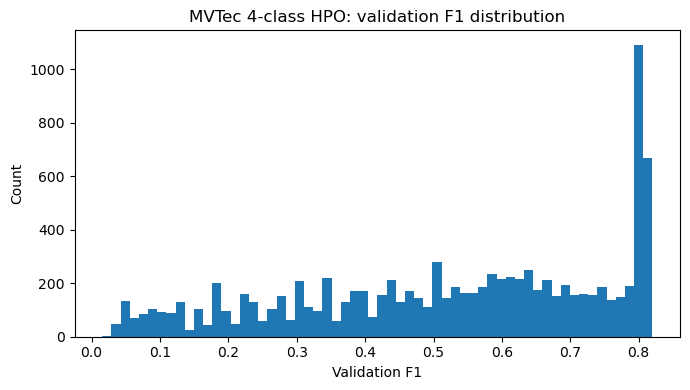

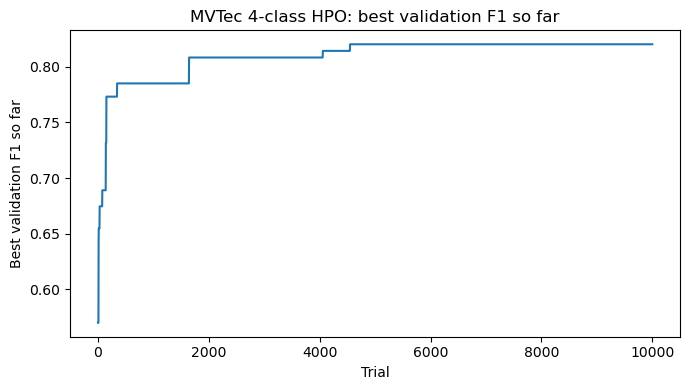

In [9]:
# Validation F1 distribution
plt.figure(figsize=(7, 4))
plt.hist(df["value"], bins=60)
plt.title("MVTec 4-class HPO: validation F1 distribution")
plt.xlabel("Validation F1")
plt.ylabel("Count")
plt.tight_layout()

plt.savefig(FIG_DIR / "mvtec_f1_distribution.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mvtec_f1_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


# Best validation F1 over trials
df_sorted = df.sort_values("number").copy()
df_sorted["best_so_far"] = df_sorted["value"].cummax()

plt.figure(figsize=(7, 4))
plt.plot(df_sorted["number"], df_sorted["best_so_far"])
plt.title("MVTec 4-class HPO: best validation F1 so far")
plt.xlabel("Trial")
plt.ylabel("Best validation F1 so far")
plt.tight_layout()

plt.savefig(FIG_DIR / "mvtec_best_f1_so_far.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mvtec_best_f1_so_far.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


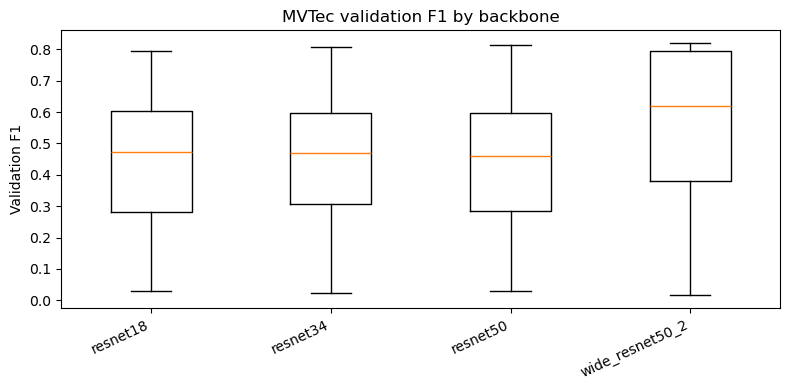

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


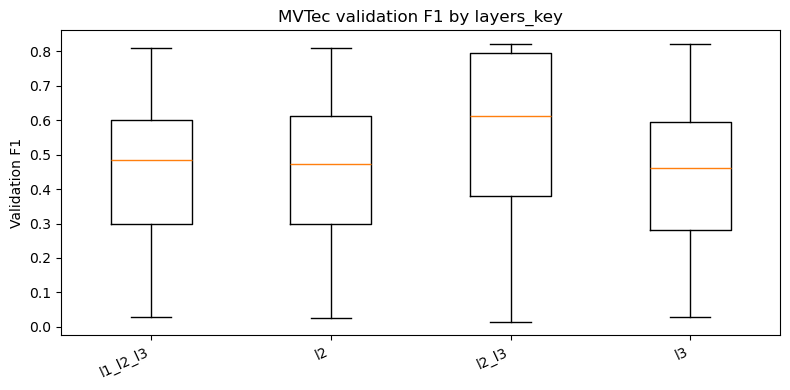

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


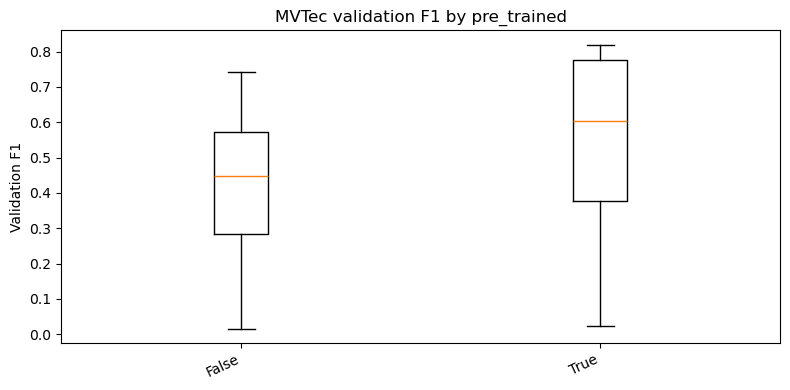

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


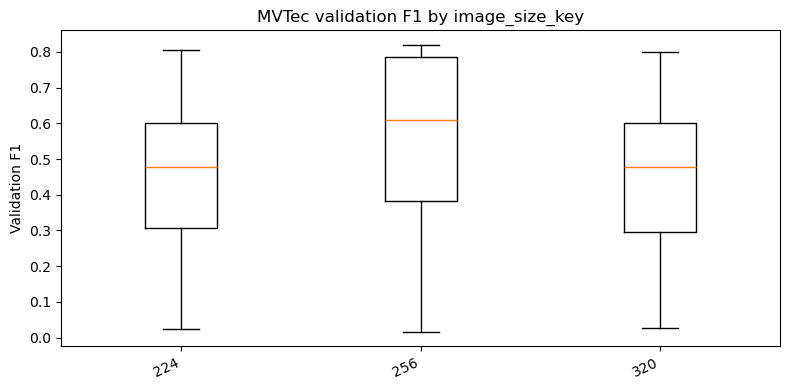

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


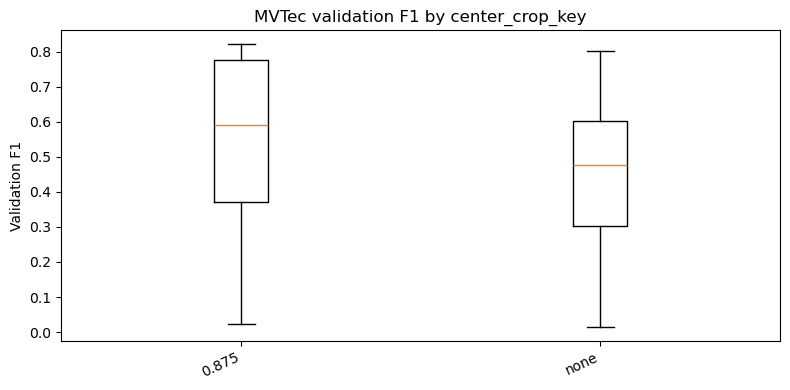

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


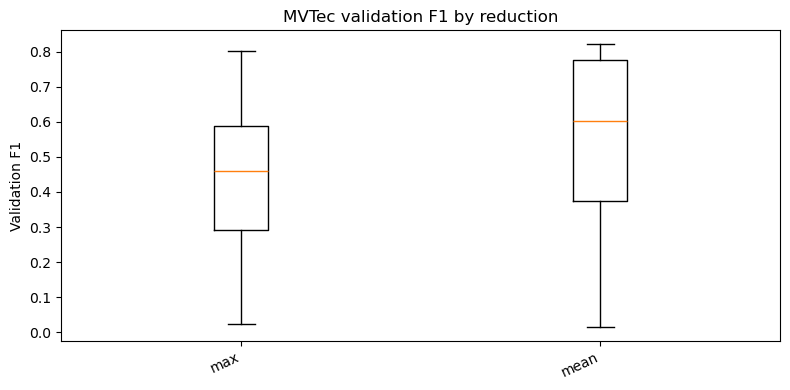

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


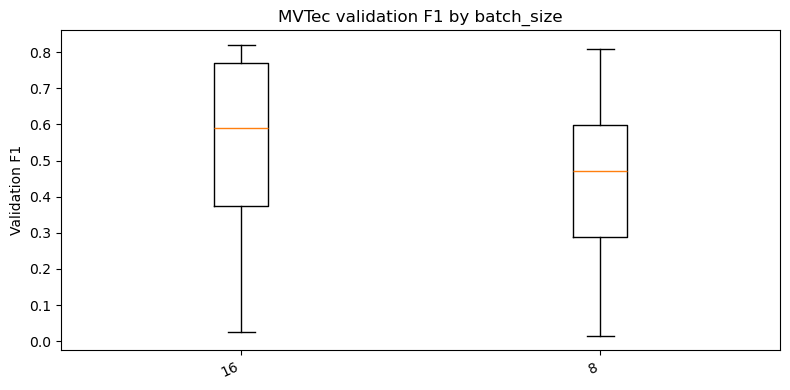

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


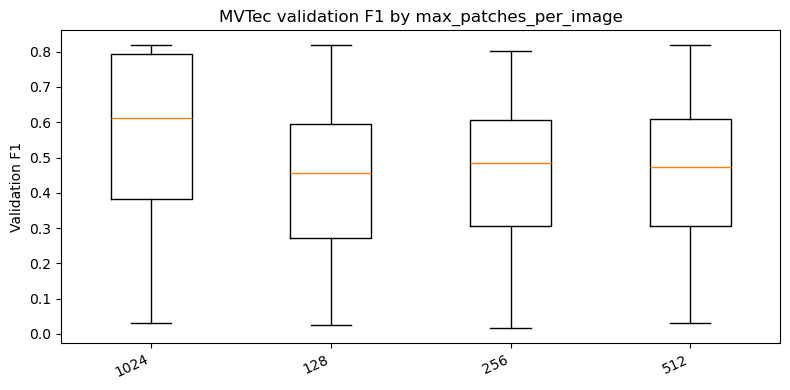

/tmp/ipykernel_1591550/3890777045.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cats, showfliers=False)


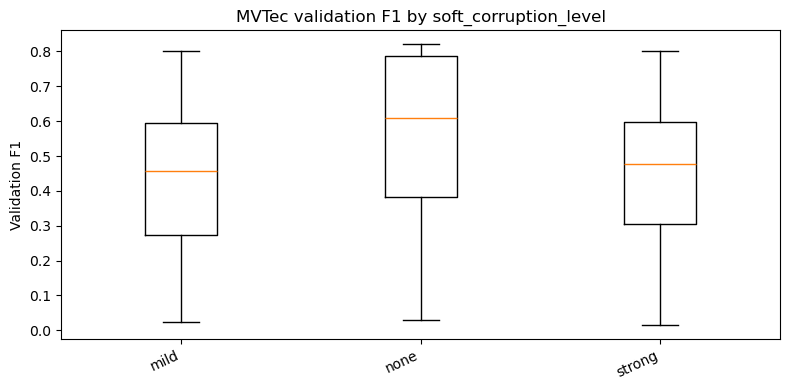

In [10]:
params_to_plot = [
    "params_backbone",
    "params_layers_key",
    "params_pre_trained",
    "params_image_size_key",
    "params_center_crop_key",
    "params_reduction",
    "params_batch_size",
    "params_max_patches_per_image",
    "params_soft_corruption_level",
]

for col in params_to_plot:
    if col not in df.columns:
        print("Skipping missing column:", col)
        continue

    g = df[[col, "value"]].dropna().copy()
    g[col] = g[col].astype(str)

    if g[col].nunique() > 20:
        print("Skipping high-cardinality column:", col, g[col].nunique())
        continue

    cats = sorted(g[col].unique().tolist())
    data = [g.loc[g[col] == c, "value"].values for c in cats]

    plt.figure(figsize=(8, 4))
    plt.boxplot(data, labels=cats, showfliers=False)
    plt.title(f"MVTec validation F1 by {col.replace('params_', '')}")
    plt.ylabel("Validation F1")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()

    safe_name = col.replace("params_", "").replace("/", "_")
    plt.savefig(FIG_DIR / f"mvtec_f1_by_{safe_name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"mvtec_f1_by_{safe_name}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [11]:
cols_to_drop = [
    "number",
    "state",
    "datetime_start",
    "datetime_complete",
    "duration",
    "system_attrs_completed_rung_0",
    "system_attrs_completed_rung_1",
    "system_attrs_completed_rung_2",
    "system_attrs_completed_rung_3",
    "user_attrs_f1_val_at_budget",
    "user_attrs_soft_train_fraction_q01",
]

df_clean = df.drop(columns=cols_to_drop, errors="ignore").copy()

print("Shape after dropping metadata columns:", df_clean.shape)
display(df_clean.head().T)

Shape after dropping metadata columns: (9976, 20)


,0,1,2,3,4
value,0.569961,0.564978,0.288997,0.332794,0.564978
params_backbone,wide_resnet50_2,wide_resnet50_2,resnet34,resnet34,wide_resnet50_2
params_batch_size,8,8,8,8,8
params_center_crop_key,0.875,0.875,0.875,0.875,0.875
params_coreset_sampling_ratio,0.055,0.055,0.099,0.003,0.055
params_image_size_key,256,256,320,256,256
params_layers_key,l3,l3,l2,l2_l3,l3
params_max_patches_per_image,1024,1024,128,512,1024
params_num_neighbors,25,25,26,25,25
params_pre_trained,True,True,True,True,True


In [12]:
rounding_rules = {
    "params_soft_train_fraction": 2,
    "params_coreset_sampling_ratio": 3,
    "params_soft_review_budget": 3,
}

for col, ndigits in rounding_rules.items():
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce").round(ndigits)

display(df_clean.head().T)

,0,1,2,3,4
value,0.569961,0.564978,0.288997,0.332794,0.564978
params_backbone,wide_resnet50_2,wide_resnet50_2,resnet34,resnet34,wide_resnet50_2
params_batch_size,8,8,8,8,8
params_center_crop_key,0.875,0.875,0.875,0.875,0.875
params_coreset_sampling_ratio,0.055,0.055,0.099,0.003,0.055
params_image_size_key,256,256,320,256,256
params_layers_key,l3,l3,l2,l2_l3,l3
params_max_patches_per_image,1024,1024,128,512,1024
params_num_neighbors,25,25,26,25,25
params_pre_trained,True,True,True,True,True


In [13]:
TARGET = "value"

FEATURES = [
    "params_backbone",
    "params_batch_size",
    "params_center_crop_key",
    "params_coreset_sampling_ratio",
    "params_image_size_key",
    "params_layers_key",
    "params_max_patches_per_image",
    "params_num_neighbors",
    "params_pre_trained",
    "params_reduction",
    "params_soft_corruption_level",
    "params_soft_review_budget",
    "params_soft_train_fraction",
]

keep_cols = [TARGET] + FEATURES

missing_cols = [c for c in keep_cols if c not in df_clean.columns]
available_cols = [c for c in keep_cols if c in df_clean.columns]

print("Expected columns:", len(keep_cols))
print("Available columns:", len(available_cols))
print("Missing columns:", missing_cols)

if missing_cols:
    print("\nAvailable parameter columns:")
    for c in sorted([c for c in df_clean.columns if c.startswith("params_")]):
        print("-", c)

Expected columns: 14
Available columns: 14
Missing columns: []


In [14]:
if missing_cols:
    raise ValueError(
        "Some expected surrogate columns are missing. "
        "Check Cell 13 output and update FEATURES to match the MVTec HPO log."
    )

df_export = df_clean.loc[:, keep_cols].copy()

before = len(df_export)
df_export = df_export.dropna(subset=keep_cols).reset_index(drop=True)
after = len(df_export)

print("Rows before dropna:", before)
print("Rows after dropna:", after)
print("Dropped rows:", before - after)

display(df_export.head())
display(df_export.describe(include="all").T)

Rows before dropna: 9976
Rows after dropna: 9976
Dropped rows: 0


,value,params_backbone,params_batch_size,params_center_crop_key,params_coreset_sampling_ratio,params_image_size_key,params_layers_key,params_max_patches_per_image,params_num_neighbors,params_pre_trained,params_reduction,params_soft_corruption_level,params_soft_review_budget,params_soft_train_fraction
0,0.569961,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50
1,0.564978,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50
2,0.288997,resnet34,8,0.875,0.099,320,l2,128,26,True,mean,none,0.11,0.61
3,0.332794,resnet34,8,0.875,0.003,256,l2_l3,512,25,True,max,strong,0.22,0.66
4,0.564978,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
value,9976.0,NaN,NaN,NaN,0.524907,0.228218,0.015625,0.347519,0.562076,0.732452,0.820249
params_backbone,9976,4,wide_resnet50_2,6917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
params_batch_size,9976.0,NaN,NaN,NaN,14.428228,3.178793,8.0,16.0,16.0,16.0,16.0
params_center_crop_key,9976,2,0.875,7994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
params_coreset_sampling_ratio,9976.0,NaN,NaN,NaN,0.035027,0.02344,0.001,0.021,0.027,0.039,0.101
params_image_size_key,9976,3,256,7317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
params_layers_key,9976,4,l2_l3,6920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
params_max_patches_per_image,9976.0,NaN,NaN,NaN,803.284683,345.438802,128.0,512.0,1024.0,1024.0,1024.0
params_num_neighbors,9976.0,NaN,NaN,NaN,7.581997,8.646676,1.0,2.0,3.0,12.0,30.0
params_pre_trained,9976,2,True,7948,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
cat_as_str = [
    "params_backbone",
    "params_center_crop_key",
    "params_image_size_key",
    "params_layers_key",
    "params_pre_trained",
    "params_reduction",
    "params_soft_corruption_level",
    "params_batch_size",
    "params_max_patches_per_image",
]

for c in cat_as_str:
    if c in df_export.columns:
        df_export[c] = df_export[c].astype(str)

num_cols = [
    "params_coreset_sampling_ratio",
    "params_num_neighbors",
    "params_soft_review_budget",
    "params_soft_train_fraction",
    TARGET,
]

for c in num_cols:
    if c in df_export.columns:
        df_export[c] = pd.to_numeric(df_export[c], errors="coerce")

before = len(df_export)
df_export = df_export.dropna(subset=num_cols).reset_index(drop=True)
after = len(df_export)

print("Rows before numeric cleaning:", before)
print("Rows after numeric cleaning:", after)
print("Dropped rows:", before - after)

print("\nDtypes:")
display(df_export.dtypes)

display(df_export.head())

Rows before numeric cleaning: 9976
Rows after numeric cleaning: 9976
Dropped rows: 0

Dtypes:


value                            float64
params_backbone                   object
params_batch_size                 object
params_center_crop_key            object
params_coreset_sampling_ratio    float64
params_image_size_key             object
params_layers_key                 object
params_max_patches_per_image      object
params_num_neighbors               int64
params_pre_trained                object
params_reduction                  object
params_soft_corruption_level      object
params_soft_review_budget        float64
params_soft_train_fraction       float64
dtype: object

,value,params_backbone,params_batch_size,params_center_crop_key,params_coreset_sampling_ratio,params_image_size_key,params_layers_key,params_max_patches_per_image,params_num_neighbors,params_pre_trained,params_reduction,params_soft_corruption_level,params_soft_review_budget,params_soft_train_fraction
0,0.569961,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50
1,0.564978,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50
2,0.288997,resnet34,8,0.875,0.099,320,l2,128,26,True,mean,none,0.11,0.61
3,0.332794,resnet34,8,0.875,0.003,256,l2_l3,512,25,True,max,strong,0.22,0.66
4,0.564978,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50


In [16]:
print("Target summary:")
display(df_export[TARGET].describe())

print("\nCategorical domains:")
for c in cat_as_str:
    if c in df_export.columns:
        vals = sorted(df_export[c].dropna().astype(str).unique().tolist())
        print(f"{c}: {vals}")

print("\nNumeric ranges:")
for c in num_cols:
    if c in df_export.columns:
        print(
            f"{c}: min={df_export[c].min():.6f}, "
            f"max={df_export[c].max():.6f}, "
            f"mean={df_export[c].mean():.6f}"
        )

Target summary:


count    9976.000000
mean        0.524907
std         0.228218
min         0.015625
25%         0.347519
50%         0.562076
75%         0.732452
max         0.820249
Name: value, dtype: float64


Categorical domains:
params_backbone: ['resnet18', 'resnet34', 'resnet50', 'wide_resnet50_2']
params_center_crop_key: ['0.875', 'none']
params_image_size_key: ['224', '256', '320']
params_layers_key: ['l1_l2_l3', 'l2', 'l2_l3', 'l3']
params_pre_trained: ['False', 'True']
params_reduction: ['max', 'mean']
params_soft_corruption_level: ['mild', 'none', 'strong']
params_batch_size: ['16', '8']
params_max_patches_per_image: ['1024', '128', '256', '512']

Numeric ranges:
params_coreset_sampling_ratio: min=0.001000, max=0.101000, mean=0.035027
params_num_neighbors: min=1.000000, max=30.000000, mean=7.581997
params_soft_review_budget: min=0.005000, max=0.500000, mean=0.291053
params_soft_train_fraction: min=0.200000, max=1.000000, mean=0.767811
value: min=0.015625, max=0.820249, mean=0.524907


In [17]:
out_path = SURROGATE_DIR / "mvtec_4class_patchcore_surrogate_dataset.csv"

df_export.to_csv(out_path, index=False)

print("Saved:", out_path)
print("Shape:", df_export.shape)

display(df_export.head())

Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv
Shape: (9976, 14)


,value,params_backbone,params_batch_size,params_center_crop_key,params_coreset_sampling_ratio,params_image_size_key,params_layers_key,params_max_patches_per_image,params_num_neighbors,params_pre_trained,params_reduction,params_soft_corruption_level,params_soft_review_budget,params_soft_train_fraction
0,0.569961,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50
1,0.564978,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50
2,0.288997,resnet34,8,0.875,0.099,320,l2,128,26,True,mean,none,0.11,0.61
3,0.332794,resnet34,8,0.875,0.003,256,l2_l3,512,25,True,max,strong,0.22,0.66
4,0.564978,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50


In [18]:
summary = {
    "study_name": study.study_name,
    "n_trials_total": len(study.trials),
    "n_complete_valid_trials": len(df),
    "n_surrogate_rows": len(df_export),
    "n_features": len(FEATURES),
    "best_validation_f1": float(df["value"].max()),
    "mean_validation_f1": float(df["value"].mean()),
    "median_validation_f1": float(df["value"].median()),
    "min_validation_f1": float(df["value"].min()),
    "max_validation_f1": float(df["value"].max()),
}

summary_df = pd.DataFrame([summary])

summary_path = TABLE_DIR / "mvtec_preprocessing_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("Saved:", summary_path)
display(summary_df.T)

Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/tables_preprocessing/mvtec_preprocessing_summary.csv


,0
study_name,mvtec_4class_patchcore_bottle_cable_capsule_hazelnut_v1.0.0
n_trials_total,10000
n_complete_valid_trials,9976
n_surrogate_rows,9976
n_features,13
best_validation_f1,0.820249
mean_validation_f1,0.524907
median_validation_f1,0.562076
min_validation_f1,0.015625
max_validation_f1,0.820249


Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/figures_preprocessing/mvtec_hpo_log_summary.pdf
Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/figures_preprocessing/mvtec_hpo_log_summary.png


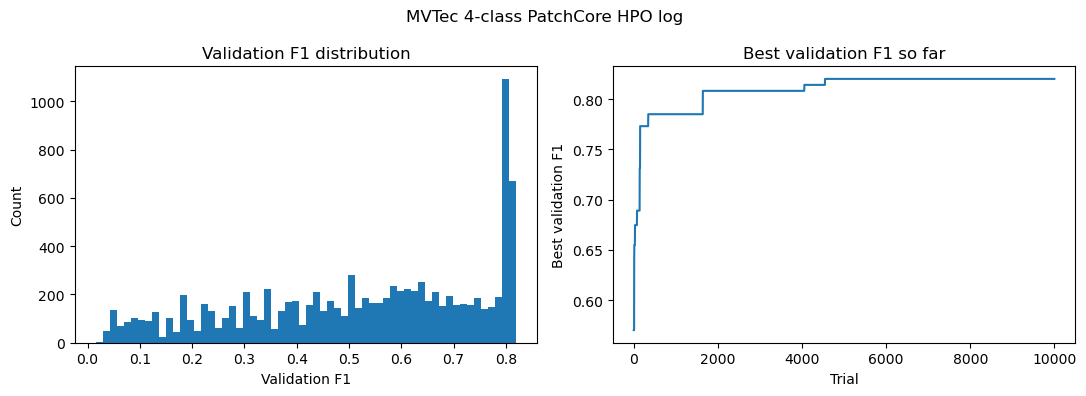

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["value"], bins=60)
axes[0].set_title("Validation F1 distribution")
axes[0].set_xlabel("Validation F1")
axes[0].set_ylabel("Count")

df_sorted = df.sort_values("number").copy()
df_sorted["best_so_far"] = df_sorted["value"].cummax()

axes[1].plot(df_sorted["number"], df_sorted["best_so_far"])
axes[1].set_title("Best validation F1 so far")
axes[1].set_xlabel("Trial")
axes[1].set_ylabel("Best validation F1")

fig.suptitle("MVTec 4-class PatchCore HPO log")
plt.tight_layout()

fig_path_pdf = FIG_DIR / "mvtec_hpo_log_summary.pdf"
fig_path_png = FIG_DIR / "mvtec_hpo_log_summary.png"

fig.savefig(fig_path_pdf, bbox_inches="tight")
fig.savefig(fig_path_png, dpi=300, bbox_inches="tight")

print("Saved:", fig_path_pdf)
print("Saved:", fig_path_png)

plt.show()